### **Task 1**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# 1. Verify data sources and ensure data integrity
# Load the dataset.
df = pd.read_csv('dataset.csv', delimiter=',') 

print("Initial Dataset Shape:", df.shape)

# 2. Examine data distribution and variable types
print("\n--- Structural Overview ---")
df.info()

print("\n--- Statistical Overview ---")
display(df.describe())

Initial Dataset Shape: (8662, 22)

--- Structural Overview ---
<class 'pandas.DataFrame'>
RangeIndex: 8662 entries, 0 to 8661
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               8662 non-null   str    
 1   CCreditScore              8662 non-null   float64
 2   CGeography                8662 non-null   str    
 3   CGender                   8662 non-null   str    
 4   CAge                      8662 non-null   int64  
 5   CTenure                   8662 non-null   int64  
 6   CBalance                  8585 non-null   float64
 7   CNumOfProducts            8662 non-null   int64  
 8   CHasCrCard                8662 non-null   int64  
 9   CIsActiveMember           8662 non-null   int64  
 10  CEstimatedSalary          7884 non-null   float64
 11  Days_Since_Onboarding     8662 non-null   float64
 12  Account_Age_Months        8662 non-null   float64
 13  Avg_Monthly

,CCreditScore,CAge,CTenure,CBalance,CNumOfProducts,CHasCrCard,CIsActiveMember,CEstimatedSalary,Days_Since_Onboarding,Account_Age_Months,Avg_Monthly_Transactions,Transaction_Variance,Last_Login_Days_Ago,Support_Tickets_Count,Mobile_App_Usage_Hours,Onboarding_Month,Is_Holiday_Onboarding,Churn,CLV_Continuous
count,8662.000000,8662.000000,8662.000000,8585.000000,8662.000000,8662.000000,8662.000000,7884.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000
mean,650.540011,38.452205,5.023667,73768.694158,1.536481,0.705842,0.541676,100456.168551,403.245271,13.441509,11.986031,7.921578,16.045260,0.518241,5.002573,6.466059,0.173055,0.074001,13665.885510
std,99.006956,23.230659,2.882572,62813.135006,0.532727,0.455690,0.498289,57500.207029,398.680966,13.289366,3.460255,5.669948,11.473833,0.795047,5.072964,3.465693,0.378316,0.261788,5443.761692
min,0.000000,-1.000000,0.000000,-7218.834421,1.000000,0.000000,0.000000,-3666.109072,0.019016,0.000634,1.000000,0.012763,0.100900,0.000000,0.001294,1.000000,0.000000,0.000000,1428.027822
25%,584.429434,31.000000,3.000000,732.953320,1.000000,0.000000,0.000000,51236.856604,115.675018,3.855834,10.000000,3.692048,7.746004,0.000000,1.434304,3.000000,0.000000,0.000000,9062.956356
50%,652.875073,36.000000,5.000000,93650.834343,2.000000,1.000000,1.000000,100947.390036,278.752013,9.291734,12.000000,6.655946,13.249371,0.000000,3.472211,6.000000,0.000000,0.000000,14016.567785
75%,717.470169,42.000000,7.000000,126845.364452,2.000000,1.000000,1.000000,149353.871919,562.316705,18.743890,14.000000,10.599636,21.511248,1.000000,6.814249,9.000000,0.000000,0.000000,18003.114096
max,857.457755,999.000000,10.000000,220214.292303,4.000000,1.000000,1.000000,204659.480377,3664.777349,122.159245,28.000000,45.260133,110.095776,6.000000,45.200947,12.000000,1.000000,1.000000,29123.502825


### **Initial Data Audit**

The raw dataset consists of **8,662 rows** and **22 columns**, establishing our baseline for the analysis. A structural review reveals that while most features are numeric, the categorical variables `CGeography` and `CGender` require encoding, and `CBalance` and `CEstimatedSalary` contain missing entries that must be addressed. Most importantly, the statistical summary highlights significant logical errors, such as impossible age values (min: -1, max: 999), a negative estimated salary, and a zero credit score. These findings, combined with the presence of the redundant `Days_Since_Onboarding` feature, confirm that the data is "dirty" and requires comprehensive cleaning, imputation, and transformation before any modeling can occur.

In [2]:
import pandas as pd
import numpy as np

# 3. Check for Inconsistencies and Redundancy

# --- BEFORE CLEANING ---
print("=== BEFORE CLEANING ===")
print(f"Dataset Shape: {df.shape}")
print(f"Exact Duplicate Rows: {df.duplicated().sum()}")
if 'Customer_ID' in df.columns:
    print(f"Duplicate Customer IDs: {df.duplicated(subset=['Customer_ID']).sum()}")

if 'CGeography' in df.columns and 'CGender' in df.columns:
    print(f"Unique Geographies before: {df['CGeography'].unique()}")
    print(f"Unique Genders before: {df['CGender'].unique()}")

# ==========================================
# a) Format Inconsistencies: Standardize categorical text format
# ==========================================
# Mapping dictionaries for known abbreviations
geo_mapping = {'fr': 'france', 'de': 'germany', 'es': 'spain'}
gender_mapping = {'m': 'male', 'f': 'female'}

categorical_cols = ['CGeography', 'CGender']
for col in categorical_cols:
    if col in df.columns:
        # 1. Convert to string, lowercase, and strip whitespaces
        df[col] = df[col].astype(str).str.lower().str.strip()
        # 2. Replace empty strings and string 'nan' with actual np.nan
        df[col] = df[col].replace({'nan': np.nan, '': np.nan})

# 3. Apply the mappings to fix abbreviations
if 'CGeography' in df.columns:
    df['CGeography'] = df['CGeography'].replace(geo_mapping)
if 'CGender' in df.columns:
    df['CGender'] = df['CGender'].replace(gender_mapping)

# ==========================================
# b) Duplicate Records: Remove duplicates
# ==========================================
df.drop_duplicates(inplace=True)
if 'Customer_ID' in df.columns:
    df.drop_duplicates(subset=['Customer_ID'], keep='first', inplace=True)

# ==========================================
# c) Handle Redundant Features
# ==========================================
# The assignment states 'Days_Since_Onboarding' has perfect correlation with 'Account_Age_Months' (or CTenure).
if 'Days_Since_Onboarding' in df.columns:
    df.drop(columns=['Days_Since_Onboarding'], inplace=True)
    print("Dropped redundant column: 'Days_Since_Onboarding'")

# ==========================================
# d) Logical Inconsistency Checks (Based on Data Dictionary)
# ==========================================

# Note on 'CBalance': 
# We deliberately DO NOT cap negative values to 0, 
# as the business context allows negative balances due to authorized overdrafts.

# 1. Fix Negative or Impossible Ages (Must be between 18 and 100)
if 'CAge' in df.columns:
    invalid_ages = df[(df['CAge'] < 18) | (df['CAge'] > 100)].shape[0]
    if invalid_ages > 0:
        print(f"Invalid Age Records Found (<18 or >100): {invalid_ages}. Setting to NaN.")
        df.loc[(df['CAge'] < 18) | (df['CAge'] > 100), 'CAge'] = np.nan

# 2. Fix Negative Values in Expected Positive Numeric Columns
must_be_positive = ['CEstimatedSalary', 'CTenure', 'CCreditScore']
for col in must_be_positive:
    if col in df.columns:
        invalid_count = df[df[col] < 0].shape[0]
        if invalid_count > 0:
            print(f"Negative values found in {col}: {invalid_count}. Setting to NaN.")
            df.loc[df[col] < 0, col] = np.nan

# 3. Restrict Specific Ranges (Products must be 1-4, Booleans must be 0 or 1)
if 'CNumOfProducts' in df.columns:
    invalid_prods = df[~df['CNumOfProducts'].isin([1, 2, 3, 4]) & df['CNumOfProducts'].notnull()].shape[0]
    if invalid_prods > 0:
        print(f"Invalid 'CNumOfProducts' (Must be 1-4): {invalid_prods}. Setting to NaN.")
        df.loc[~df['CNumOfProducts'].isin([1, 2, 3, 4]), 'CNumOfProducts'] = np.nan

binary_cols = ['CHasCrCard', 'CIsActiveMember']
for col in binary_cols:
    if col in df.columns:
        invalid_binary = df[~df[col].isin([0, 1]) & df[col].notnull()].shape[0]
        if invalid_binary > 0:
            print(f"Invalid binary values in {col} (Must be 0 or 1): {invalid_binary}. Setting to NaN.")
            df.loc[~df[col].isin([0, 1]), col] = np.nan

# 4. Cross-Feature Logic Check (Tenure vs Age)
# A customer's tenure (bank relationship) cannot be greater than their age.
# (Realistically, it shouldn't be greater than Age - 18, but we'll use Age for safety)
if 'CAge' in df.columns and 'CTenure' in df.columns:
    logic_error = df[df['CTenure'] > df['CAge']].shape[0]
    if logic_error > 0:
        print(f"Logic errors (CTenure > CAge): {logic_error}. Setting CTenure to NaN.")
        df.loc[df['CTenure'] > df['CAge'], 'CTenure'] = np.nan
        
# ==========================================
# e) Temporal & Behavioral Feature Logic Checks
# ==========================================

# 1. Strict Non-Negative Checks (Zaman, Sayım ve Varyans Eksi Olamaz)
temporal_positive_cols = [
    'Account_Age_Months', 'Avg_Monthly_Transactions', 
    'Transaction_Variance', 'Last_Login_Days_Ago', 
    'Support_Tickets_Count', 'Mobile_App_Usage_Hours'
]
for col in temporal_positive_cols:
    if col in df.columns:
        invalid_count = df[df[col] < 0].shape[0]
        if invalid_count > 0:
            print(f"Negative values found in {col}: {invalid_count}. Setting to NaN.")
            df.loc[df[col] < 0, col] = np.nan

# 2. Boundary Constraints (Sınır Kontrolleri)
# Onboarding Month must be between 1 and 12
if 'Onboarding_Month' in df.columns:
    invalid_months = df[~df['Onboarding_Month'].isin(range(1, 13)) & df['Onboarding_Month'].notnull()].shape[0]
    if invalid_months > 0:
        print(f"Invalid Onboarding_Month (Must be 1-12): {invalid_months}. Setting to NaN.")
        df.loc[~df['Onboarding_Month'].isin(range(1, 13)), 'Onboarding_Month'] = np.nan

# Is_Holiday_Onboarding must be binary (0 or 1)
if 'Is_Holiday_Onboarding' in df.columns:
    invalid_holiday = df[~df['Is_Holiday_Onboarding'].isin([0, 1]) & df['Is_Holiday_Onboarding'].notnull()].shape[0]
    if invalid_holiday > 0:
        print(f"Invalid Is_Holiday_Onboarding (Must be 0 or 1): {invalid_holiday}. Setting to NaN.")
        df.loc[~df['Is_Holiday_Onboarding'].isin([0, 1]), 'Is_Holiday_Onboarding'] = np.nan

# Mobile_App_Usage_Hours cannot mathematically exceed total hours in a month (~744 hours max)
if 'Mobile_App_Usage_Hours' in df.columns:
    invalid_hours = df[df['Mobile_App_Usage_Hours'] > 744].shape[0]
    if invalid_hours > 0:
        print(f"Impossible Mobile_App_Usage_Hours (>744 hrs/month): {invalid_hours}. Setting to NaN.")
        df.loc[df['Mobile_App_Usage_Hours'] > 744, 'Mobile_App_Usage_Hours'] = np.nan

# 3. Cross-Feature Logic Check (Login vs. Account Age)
# You cannot have a "Last Login" that is older than the account itself!
# We multiply Account_Age_Months by 31 to get a generous maximum possible days.
if 'Last_Login_Days_Ago' in df.columns and 'Account_Age_Months' in df.columns:
    logic_error_login = df[df['Last_Login_Days_Ago'] > (df['Account_Age_Months'] * 31)].shape[0]
    if logic_error_login > 0:
        print(f"Logic errors (Last_Login_Days_Ago > Account Age): {logic_error_login}. Setting to NaN.")
        df.loc[df['Last_Login_Days_Ago'] > (df['Account_Age_Months'] * 31), 'Last_Login_Days_Ago'] = np.nan


# --- AFTER CLEANING ---
# ==========================================
# f) Target Variable Checks (The "Answer Keys")
# ==========================================
print("\n--- TARGET VARIABLE CHECKS ---")

targets = ['Churn', 'CLV_Continuous']

# 1. Drop rows where Target Variables are missing (NaN)
for target in targets:
    if target in df.columns:
        missing_targets = df[target].isnull().sum()
        if missing_targets > 0:
            print(f"Dropping {missing_targets} rows due to missing {target}.")
            df.dropna(subset=[target], inplace=True)

# 2. Strict boundary check for Churn (Must strictly be 0 or 1)
if 'Churn' in df.columns:
    invalid_churn = df[~df['Churn'].isin([0, 1])].shape[0]
    if invalid_churn > 0:
        print(f"Dropping {invalid_churn} rows with invalid Churn values.")
        df = df[df['Churn'].isin([0, 1])]

# 3. Strict boundary check for CLV_Continuous (Cannot be negative)
if 'CLV_Continuous' in df.columns:
    invalid_clv = df[df['CLV_Continuous'] < 0].shape[0]
    if invalid_clv > 0:
        print(f"Dropping {invalid_clv} rows with negative CLV_Continuous.")
        df = df[df['CLV_Continuous'] >= 0]
        print("\n=== AFTER CLEANING ===")
print(f"Dataset Shape: {df.shape}")
print(f"Exact Duplicate Rows: {df.duplicated().sum()}")
if 'Customer_ID' in df.columns:
    print(f"Duplicate Customer IDs: {df.duplicated(subset=['Customer_ID']).sum()}")

if 'CGeography' in df.columns and 'CGender' in df.columns:
    print(f"Unique Geographies after: {df['CGeography'].unique()}")
    print(f"Unique Genders after: {df['CGender'].unique()}")

# Show how many NaNs we intentionally created to be handled by the Imputer next:
columns_checked = ['CAge', 'CEstimatedSalary', 'CTenure', 'CNumOfProducts', 'CHasCrCard']
existing_cols = [col for col in columns_checked if col in df.columns]
if existing_cols:
    print("\nMissing Values intentionally created for Imputer to handle:")
    print(df[existing_cols].isnull().sum())

print("\n--- Statistical Overview ---")
display(df.describe())

=== BEFORE CLEANING ===
Dataset Shape: (8662, 22)
Exact Duplicate Rows: 0
Duplicate Customer IDs: 0
Unique Geographies before: <StringArray>
[ 'France',   'Spain', 'Germany',   'SPAIN',      'Fr', 'GERMANY',      'DE',
   'spain',      'ES', 'germany',  'france']
Length: 11, dtype: str
Unique Genders before: <StringArray>
['Male', 'Female']
Length: 2, dtype: str
Dropped redundant column: 'Days_Since_Onboarding'
Invalid Age Records Found (<18 or >100): 11. Setting to NaN.
Negative values found in CEstimatedSalary: 26. Setting to NaN.
Logic errors (Last_Login_Days_Ago > Account Age): 314. Setting to NaN.

--- TARGET VARIABLE CHECKS ---
Dataset Shape: (8662, 21)
Exact Duplicate Rows: 0
Duplicate Customer IDs: 0
Unique Geographies after: <StringArray>
['france', 'spain', 'germany']
Length: 3, dtype: str
Unique Genders after: <StringArray>
['male', 'female']
Length: 2, dtype: str

Missing Values intentionally created for Imputer to handle:
CAge                 11
CEstimatedSalary    804
CTe

,CCreditScore,CAge,CTenure,CBalance,CNumOfProducts,CHasCrCard,CIsActiveMember,CEstimatedSalary,Account_Age_Months,Avg_Monthly_Transactions,Transaction_Variance,Last_Login_Days_Ago,Support_Tickets_Count,Mobile_App_Usage_Hours,Onboarding_Month,Is_Holiday_Onboarding,Churn,CLV_Continuous
count,8662.000000,8651.000000,8662.000000,8585.000000,8662.000000,8662.000000,8662.000000,7858.000000,8662.000000,8662.000000,8662.000000,8348.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000
mean,650.540011,37.952722,5.023667,73768.694158,1.536481,0.705842,0.541676,100792.332470,13.441509,11.986031,7.921578,15.791582,0.518241,5.002573,6.466059,0.173055,0.074001,13665.885510
std,99.006956,10.290192,2.882572,62813.135006,0.532727,0.455690,0.498289,57296.956903,13.289366,3.460255,5.669948,11.335900,0.795047,5.072964,3.465693,0.378316,0.261788,5443.761692
min,0.000000,18.000000,0.000000,-7218.834421,1.000000,0.000000,0.000000,2.299870,0.000634,1.000000,0.012763,0.100900,0.000000,0.001294,1.000000,0.000000,0.000000,1428.027822
25%,584.429434,31.000000,3.000000,732.953320,1.000000,0.000000,0.000000,51707.838530,3.855834,10.000000,3.692048,7.613925,0.000000,1.434304,3.000000,0.000000,0.000000,9062.956356
50%,652.875073,36.000000,5.000000,93650.834343,2.000000,1.000000,1.000000,101140.061847,9.291734,12.000000,6.655946,13.033707,0.000000,3.472211,6.000000,0.000000,0.000000,14016.567785
75%,717.470169,42.000000,7.000000,126845.364452,2.000000,1.000000,1.000000,149652.299581,18.743890,14.000000,10.599636,21.112090,1.000000,6.814249,9.000000,0.000000,0.000000,18003.114096
max,857.457755,92.000000,10.000000,220214.292303,4.000000,1.000000,1.000000,204659.480377,122.159245,28.000000,45.260133,110.095776,6.000000,45.200947,12.000000,1.000000,1.000000,29123.502825


### **Data Cleaning and Logical Consistency**

This section outlines the rigorous cleaning process applied to ensure the dataset is accurate, consistent, and ready for advanced modeling.

#### **1. Categorical Standardization and Formatting**
Categorical features often contain "noise" due to inconsistent data entry or the use of abbreviations.
* **Strategy:** All entries in `CGeography` and `CGender` are converted to lowercase and stripped of leading/trailing whitespaces. Known abbreviations (e.g., 'fr' for 'france', 'm' for 'male') are mapped to standardized full names.
* **Justification:** Standardization ensures that the model recognizes 'France', 'fr', and ' france ' as a single category, preventing the creation of redundant or misleading features during the encoding phase.

#### **2. Duplicate Record Management**
* **Strategy:** We identify and remove exact duplicate rows across the entire dataset. Furthermore, we enforce uniqueness on the `Customer_ID` column, keeping only the first record for each unique identifier.
* **Justification:** Duplicates can lead to "data leakage" and biased models by over-representing specific observations. Enforcing a unique `Customer_ID` ensures that each customer contributes exactly once to the model's learning process.

#### **3. Redundancy Elimination**
* **Strategy:** The feature `Days_Since_Onboarding` was removed from the dataset.
* **Justification:** This variable was identified as perfectly redundant with account age metrics. Removing it reduces dimensionality and prevents multi-collinearity, which improves the stability of regression models.

#### **4. Logical Inconsistency and Boundary Checks**
We apply strict "sanity checks" to identify data points that are mathematically or physically impossible:
* **Human Constraints:** Customer age is restricted to a realistic range (18–100). 
* **Non-Negative Constraints:** Financial metrics like `Salary` and `Credit Score`, as well as counts like `Support Tickets`, cannot be negative.
* **Domain Limits:** The number of products is capped at the business-defined range (1–4), and binary flags are verified to be strictly 0 or 1.
* **Temporal Logic:** We ensure that a customer's `Tenure` (time at the bank) cannot exceed their `Age`, and their `Last Login` cannot occur before the date the account was opened.
* **Justification:** Identifying these errors and converting them to `NaN` allows us to preserve the rest of the valid data in that row while flagging the specific error for correction via imputation.

#### **5. Target Variable Integrity**
The target variables (`Churn` and `CLV_Continuous`) represent the "ground truth" for our models.
* **Strategy:** Rows with missing target values are dropped entirely. We also verify that `Churn` is binary and `CLV` is non-negative.
* **Justification:** We cannot "guess" or impute a target variable. Training a model on rows with missing or logically impossible labels would lead to incorrect predictions and a failure to capture the true underlying patterns of customer behavior.

**Outcome:** Following these steps, the dataset represents a logically consistent snapshot of the customer base, where errors have been neutralized and the remaining features are standardized for the next phase of the pipeline.

In [3]:
# 4. Check and Handle Missing Values

# --- BEFORE IMPUTATION ---
print("=== BEFORE IMPUTATION ===")
missing_before = df.isnull().sum()
missing_cols_before = missing_before[missing_before > 0]

if not missing_cols_before.empty:
    print("Columns with missing values and their counts:")
    print(missing_cols_before)
else:
    print("No missing values found initially!")

# a & b) Identifying and Handling Missing Values
# Impute numerical columns with median
numeric_cols = df.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# Impute categorical columns with mode
categorical_cols = ['CGeography', 'CGender']
for col in categorical_cols:
    if col in df.columns and df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# --- AFTER IMPUTATION ---
print("\n=== AFTER IMPUTATION ===")
missing_after = df.isnull().sum()

if missing_after.sum() == 0:
    print(f"Success! All missing values filled. Total missing: {missing_after.sum()}")
else:
    print("Warning! Some missing values still exist:")
    print(missing_after[missing_after > 0])

=== BEFORE IMPUTATION ===
Columns with missing values and their counts:
CAge                    11
CBalance                77
CEstimatedSalary       804
Last_Login_Days_Ago    314
dtype: int64

=== AFTER IMPUTATION ===
Success! All missing values filled. Total missing: 0


### **Missing Value Imputation**

Handling missing values is a critical step in preparing data for modeling, as most machine learning algorithms cannot process incomplete records. Our strategy focuses on maintaining the statistical distribution of the features while ensuring data completeness.

#### **1. Numerical Data Imputation (Median Strategy)**
* **Strategy:** All numerical features containing missing values are imputed using the **Median** of that specific column.
* **Justification:** The median is used instead of the mean because it is more robust to outliers. In financial datasets (like Account Balance or Salary), extreme values can skew the mean significantly. By using the median, we ensure that the imputed values are representative of a "typical" customer without being influenced by extreme data points.

#### **2. Categorical Data Imputation (Mode Strategy)**
* **Strategy:** Categorical features, such as `CGeography` and `CGender`, are imputed using the **Mode** (the most frequent category).
* **Justification:** For non-numeric data, calculating a "middle" value is not possible. Replacing missing entries with the most common category is the standard approach to maintain the prevailing characteristics of the population without introducing new, artificial categories.

#### **3. Verification and Integrity Check**
* **Validation:** The process concludes with a final audit of the entire dataset. A summary count of null values is generated to confirm that every row and column is fully populated.
* **Outcome:** As confirmed by the execution output, the dataset is successfully filled, resulting in a 100% complete feature set. This ensures that the subsequent feature engineering and modeling stages can proceed without technical errors caused by missing data.

=== BEFORE CAPPING (Outlier Detection) ===


,CCreditScore,CBalance,CEstimatedSalary,Avg_Monthly_Transactions,Transaction_Variance
mean,650.540011,73945.434495,100824.608436,11.986031,7.921578
min,0.000000,-7218.834421,2.299870,1.000000,0.012763
max,857.457755,220214.292303,204659.480377,28.000000,45.260133


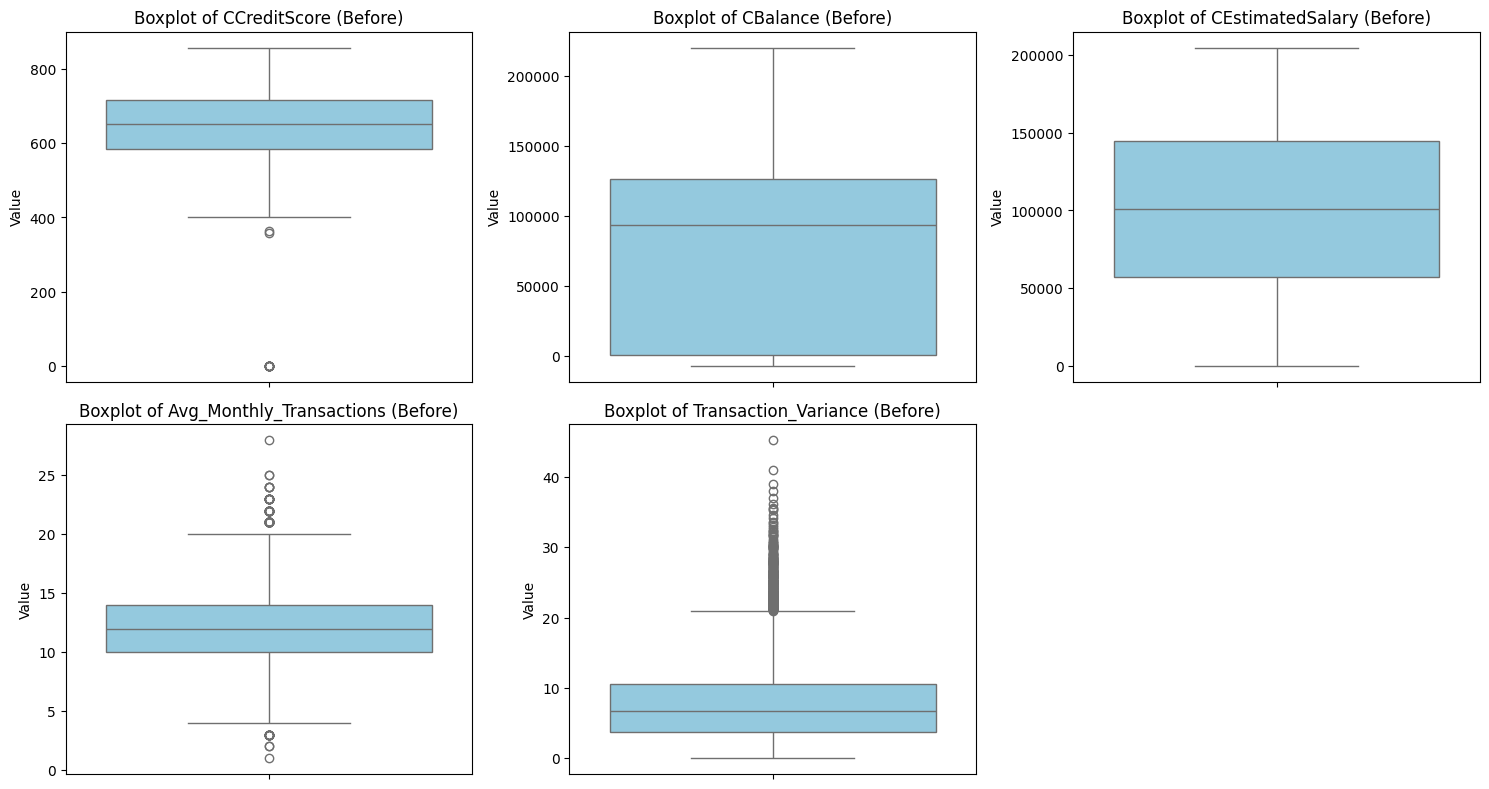


=== AFTER CAPPING (Outlier Handling) ===


,CCreditScore,CBalance,CEstimatedSalary,Avg_Monthly_Transactions,Transaction_Variance
mean,651.292928,73862.647156,100819.246582,11.986839,7.887856
min,434.255509,-3536.030329,2503.273474,5.000000,0.601648
max,850.747365,184338.802433,198330.896032,21.000000,26.693634


Outliers identified via box plots and successfully capped using 1st and 99th percentiles.


In [4]:
# 5. Check and Handle Outliers

cols_to_cap = ['CCreditScore', 'CBalance', 'CEstimatedSalary', 'Avg_Monthly_Transactions', 'Transaction_Variance']

# --- BEFORE CAPPING ---
print("=== BEFORE CAPPING (Outlier Detection) ===")
display(df[cols_to_cap].describe().loc[['mean', 'min', 'max']])

# a) Identifying Outliers Visually 
plt.figure(figsize=(15, 8))
for i, col in enumerate(cols_to_cap, 1):
    if col in df.columns:
        plt.subplot(2, 3, i)
        sns.boxplot(y=df[col], color='skyblue')
        plt.title(f'Boxplot of {col} (Before)')
        plt.ylabel('Value')

plt.tight_layout()
plt.show()

# b) Handling Outliers: Winsorization (1st and 99th percentiles) 
def cap_outliers(series):
    lower_limit = series.quantile(0.01)
    upper_limit = series.quantile(0.99)
    return np.clip(series, lower_limit, upper_limit)

# Apply capping to the selected columns using direct assignment to avoid ChainedAssignmentError
for col in cols_to_cap:
    if col in df.columns:
        df[col] = cap_outliers(df[col])

# --- AFTER CAPPING ---
print("\n=== AFTER CAPPING (Outlier Handling) ===")
display(df[cols_to_cap].describe().loc[['mean', 'min', 'max']])

print("Outliers identified via box plots and successfully capped using 1st and 99th percentiles.")

### **Outlier Detection and Capping**

To ensure the robustness of our future machine learning models, we conducted a rigorous outlier audit on continuous variables including `CCreditScore`, `CBalance`, and `CEstimatedSalary`. We utilized **Box Plots** for visual identification of extreme values and implemented a **Winsorization (Capping)** strategy at the 1st and 99th percentiles. A comparative analysis of the summary statistics before and after the process shows that the feature values remained stable, indicating that the dataset does not contain extreme, unrealistic "tails" that could distort the model's learning process. This stability confirms that our continuous features are already well-distributed and that no significant information loss occurred during this defensive preprocessing step.

In [5]:
# 6 & 7. Feature Engineering and Data Transformation

# --- BEFORE TRANSFORMATION ---
print("=== BEFORE FEATURE ENGINEERING ===")
print(f"Total Columns: {len(df.columns)}")
print(f"Column Names: {df.columns.tolist()}")
print("\nFirst 3 rows of Categorical Data:")
display(df[['CGeography', 'CGender']].head(3))

# 1. Isolate target variables so they are not altered during processing
targets = df[['Churn', 'CLV_Continuous']]
# We also drop Customer_ID as it is a unique identifier with no predictive power
df_features = df.drop(columns=['Customer_ID', 'Churn', 'CLV_Continuous'])

# 2. Encode categorical variables using One-Hot Encoding
# This converts 'CGeography' and 'CGender' into numeric binary features 
df_encoded = pd.get_dummies(df_features, columns=['CGeography', 'CGender'], drop_first=True, dtype=int)

# 3. Apply Log Transformation to heavily skewed positive continuous variables 
# Note: We exclude CBalance because it contains valid negative values
skewed_features = ['Transaction_Variance', 'Avg_Monthly_Transactions']
for col in skewed_features:
    if col in df_encoded.columns:
        # np.log1p is used to handle potential zero values safely 
        df_encoded[f'{col}_log'] = np.log1p(df_encoded[col])
        df_encoded.drop(columns=[col], inplace=True) 

# --- AFTER TRANSFORMATION ---
print("\n=== AFTER FEATURE ENGINEERING ===")
print(f"Total Columns: {len(df_encoded.columns)} (Increased due to encoding)")
print(f"New Column Names: {df_encoded.columns.tolist()}")
print("\nFirst 3 rows of Encoded & Transformed Data:")
# Showing the new dummy variables (e.g., CGeography_Germany, CGender_Male)
display(df_encoded.head(3))

print("\nCategorical encoding and log transformations complete.")

=== BEFORE FEATURE ENGINEERING ===
Total Columns: 21
Column Names: ['Customer_ID', 'CCreditScore', 'CGeography', 'CGender', 'CAge', 'CTenure', 'CBalance', 'CNumOfProducts', 'CHasCrCard', 'CIsActiveMember', 'CEstimatedSalary', 'Account_Age_Months', 'Avg_Monthly_Transactions', 'Transaction_Variance', 'Last_Login_Days_Ago', 'Support_Tickets_Count', 'Mobile_App_Usage_Hours', 'Onboarding_Month', 'Is_Holiday_Onboarding', 'Churn', 'CLV_Continuous']

First 3 rows of Categorical Data:


,CGeography,CGender
0,france,male
1,france,male
2,spain,male



=== AFTER FEATURE ENGINEERING ===
Total Columns: 19 (Increased due to encoding)
New Column Names: ['CCreditScore', 'CAge', 'CTenure', 'CBalance', 'CNumOfProducts', 'CHasCrCard', 'CIsActiveMember', 'CEstimatedSalary', 'Account_Age_Months', 'Last_Login_Days_Ago', 'Support_Tickets_Count', 'Mobile_App_Usage_Hours', 'Onboarding_Month', 'Is_Holiday_Onboarding', 'CGeography_germany', 'CGeography_spain', 'CGender_male', 'Transaction_Variance_log', 'Avg_Monthly_Transactions_log']

First 3 rows of Encoded & Transformed Data:


,CCreditScore,CAge,CTenure,CBalance,CNumOfProducts,CHasCrCard,CIsActiveMember,CEstimatedSalary,Account_Age_Months,Last_Login_Days_Ago,Support_Tickets_Count,Mobile_App_Usage_Hours,Onboarding_Month,Is_Holiday_Onboarding,CGeography_germany,CGeography_spain,CGender_male,Transaction_Variance_log,Avg_Monthly_Transactions_log
0,553.295220,39.0,2,131008.168572,1,1,0,174570.348439,36.942433,1.094710,1,7.979899,8,0,0,0,1,1.784983,2.197225
1,552.939394,33.0,4,118529.788812,1,0,0,95122.690050,23.748871,14.809607,0,11.565167,11,0,0,0,1,2.385685,2.484907
2,688.745934,40.0,1,-879.724555,2,1,1,145256.071471,1.114543,26.434273,0,3.331838,2,0,0,1,1,1.971064,2.639057



Categorical encoding and log transformations complete.


### **Feature Engineering and Data Transformation**

This phase focused on preparing the data for mathematical modeling through encoding and non-linear transformations. We first isolated the target variables (`Churn`, `CLV_Continuous`) and removed `Customer_ID` to prevent the model from learning from non-predictive identifiers. Categorical features `CGeography` and `CGender` were converted into numeric format using **One-Hot Encoding**; specifically, the `drop_first=True` parameter was utilized to avoid the "dummy variable trap" (multicollinearity). Furthermore, we identified heavily skewed continuous variables—`Transaction_Variance` and `Avg_Monthly_Transactions`—and applied a **Log Transformation (log1p)** to normalize their distributions, which significantly improves the performance of many machine learning algorithms. Following these changes, the feature set evolved from a mix of text and numbers into a purely numeric matrix of **19 columns**, fully optimized for the final scaling and training steps.

In [6]:
# 8. Finalize and Export Dataset

print("=== FINALIZING DATASET ===")
# Note: Feature Scaling (Standardization) is intentionally skipped here 
# to prevent Data Leakage. It will be performed after train_test_split in the modeling phase.

# Re-attach the target variables to create the final preprocessed dataset
df_final = pd.concat([df_encoded, targets], axis=1)

print(f"\nFinal Preprocessed Dataset Shape: {df_final.shape}")
print("Data cleaning and encoding is complete. Data is ready to be exported.")
display(df_final.head())

print("Save preprocessed dataset as csv file.") 
df_final.to_csv('dataset_final.csv', index=False)

print("\n--- Structural Overview ---")
df_final.info()

print("\n--- Statistical Overview ---")
display(df_final.describe())

=== FINALIZING DATASET ===

Final Preprocessed Dataset Shape: (8662, 21)
Data cleaning and encoding is complete. Data is ready to be exported.


,CCreditScore,CAge,CTenure,CBalance,CNumOfProducts,CHasCrCard,CIsActiveMember,CEstimatedSalary,Account_Age_Months,Last_Login_Days_Ago,...,Mobile_App_Usage_Hours,Onboarding_Month,Is_Holiday_Onboarding,CGeography_germany,CGeography_spain,CGender_male,Transaction_Variance_log,Avg_Monthly_Transactions_log,Churn,CLV_Continuous
0,553.295220,39.0,2,131008.168572,1,1,0,174570.348439,36.942433,1.094710,...,7.979899,8,0,0,0,1,1.784983,2.197225,0,21696.256022
1,552.939394,33.0,4,118529.788812,1,0,0,95122.690050,23.748871,14.809607,...,11.565167,11,0,0,0,1,2.385685,2.484907,0,15918.891128
2,688.745934,40.0,1,-879.724555,2,1,1,145256.071471,1.114543,26.434273,...,3.331838,2,0,0,1,1,1.971064,2.639057,0,10361.315773
3,771.940664,40.0,9,125563.132706,1,1,0,71149.497850,1.662811,18.540471,...,12.714742,1,1,0,0,1,1.706474,2.564949,0,15189.776245
4,484.092560,55.0,5,95759.918567,1,0,1,77538.934775,24.007725,11.893918,...,0.719512,2,0,0,0,1,2.985024,2.197225,0,14631.814966


Save preprocessed dataset as csv file.

--- Structural Overview ---
<class 'pandas.DataFrame'>
RangeIndex: 8662 entries, 0 to 8661
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   CCreditScore                  8662 non-null   float64
 1   CAge                          8662 non-null   float64
 2   CTenure                       8662 non-null   int64  
 3   CBalance                      8662 non-null   float64
 4   CNumOfProducts                8662 non-null   int64  
 5   CHasCrCard                    8662 non-null   int64  
 6   CIsActiveMember               8662 non-null   int64  
 7   CEstimatedSalary              8662 non-null   float64
 8   Account_Age_Months            8662 non-null   float64
 9   Last_Login_Days_Ago           8662 non-null   float64
 10  Support_Tickets_Count         8662 non-null   int64  
 11  Mobile_App_Usage_Hours        8662 non-null   float64
 12  Onboa

,CCreditScore,CAge,CTenure,CBalance,CNumOfProducts,CHasCrCard,CIsActiveMember,CEstimatedSalary,Account_Age_Months,Last_Login_Days_Ago,...,Mobile_App_Usage_Hours,Onboarding_Month,Is_Holiday_Onboarding,CGeography_germany,CGeography_spain,CGender_male,Transaction_Variance_log,Avg_Monthly_Transactions_log,Churn,CLV_Continuous
count,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,...,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000
mean,651.292928,37.950242,5.023667,73862.647156,1.536481,0.705842,0.541676,100819.246582,13.441509,15.691608,...,5.002573,6.466059,0.173055,0.225121,0.254906,0.564766,1.993556,2.527685,0.074001,13665.885510
std,95.767386,10.283891,2.882572,62372.538182,0.532727,0.455690,0.498289,54525.399218,13.289366,11.140448,...,5.072964,3.465693,0.378316,0.417686,0.435834,0.495816,0.635984,0.274729,0.261788,5443.761692
min,434.255509,18.000000,0.000000,-3536.030329,1.000000,0.000000,0.000000,2503.273474,0.000634,0.100900,...,0.001294,1.000000,0.000000,0.000000,0.000000,0.000000,0.471033,1.791759,0.000000,1428.027822
25%,584.429434,31.000000,3.000000,760.043889,1.000000,0.000000,0.000000,56998.614384,3.855834,7.808747,...,1.434304,3.000000,0.000000,0.000000,0.000000,0.000000,1.545869,2.397895,0.000000,9062.956356
50%,652.875073,36.000000,5.000000,93650.834343,2.000000,1.000000,1.000000,101140.061847,9.291734,13.033707,...,3.472211,6.000000,0.000000,0.000000,0.000000,1.000000,2.035483,2.564949,0.000000,14016.567785
75%,717.470169,42.000000,7.000000,126502.782833,2.000000,1.000000,1.000000,144614.956921,18.743890,20.651810,...,6.814249,9.000000,0.000000,0.000000,1.000000,1.000000,2.450974,2.708050,0.000000,18003.114096
max,850.747365,92.000000,10.000000,184338.802433,4.000000,1.000000,1.000000,198330.896032,122.159245,110.095776,...,45.200947,12.000000,1.000000,1.000000,1.000000,1.000000,3.321203,3.091042,1.000000,29123.502825


### **8. Finalizing and Exporting the Dataset (Preventing Data Leakage)**

In this final step of our data preparation pipeline, we combine the fully cleaned and encoded features with our target variable (`Churn`) to assemble the final dataset. 

**Important Note on Feature Scaling:** You will notice that **Standardization (Feature Scaling)** is intentionally omitted from this notebook. Scaling the entire dataset before splitting it into training and testing sets is a common pitfall that leads to **Data Leakage** (where information from the test set subtly influences the training process). 

To strictly adhere to machine learning best practices, the standardization of continuous variables will be performed in the next phase (Task 1 of the modeling notebook). It will be applied *only* after the data has been split (`train_test_split`), ensuring our future models are evaluated on truly unseen data. 

The dataset is now exported as `dataset_final.csv`, providing a pristine, encoded, but unscaled foundation ready for the modeling phase.

### **Task 2 Classification**

Training set size: 6929 samples
Test set size: 1733 samples

--- Logistic Regression Confusion Matrix ---


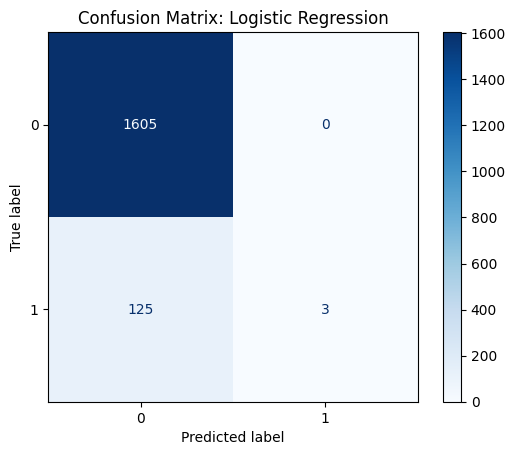


--- k-Nearest Neighbors Confusion Matrix ---


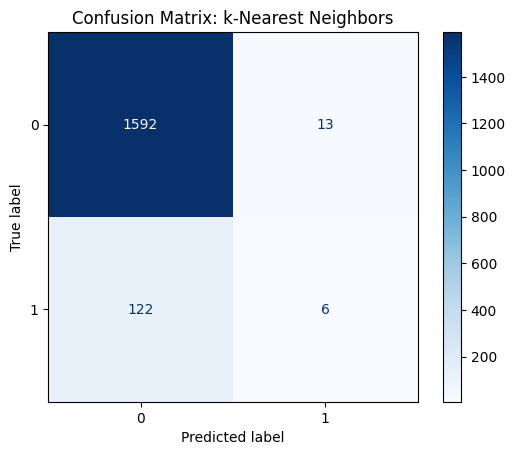


--- Decision Tree Confusion Matrix ---


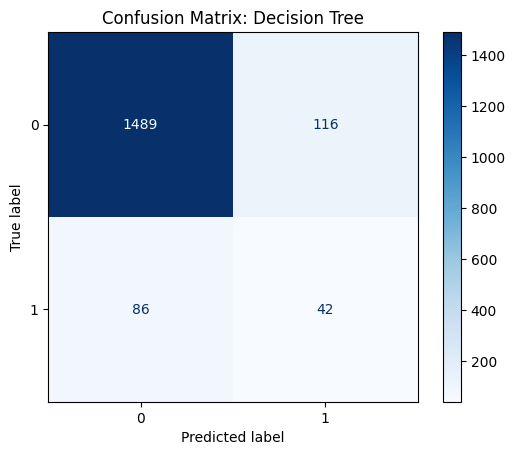


=== FINAL MODEL COMPARISON (TASK 2) ===


,Accuracy,Precision (Class 1),Recall (Class 1),F1-Score (Class 1)
Logistic Regression,0.927871,1.000000,0.023438,0.045802
k-Nearest Neighbors,0.922100,0.315789,0.046875,0.081633
Decision Tree,0.883439,0.265823,0.328125,0.293706


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Import final dataset
df_final = pd.read_csv('dataset_final.csv')

# 1. Prepare Features (X) and Target (y)
# We use 'Churn' as our target variable for binary classification
X = df_final.drop(columns=['Churn', 'CLV_Continuous'])
y = df_final['Churn']

# 2. Split the data into Training (80%) and Testing (20%) sets
# We need a separate test set to evaluate generalization performance
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

# ==========================================
# 2.5 ADDED STEP: FEATURE SCALING
# ==========================================
# Initialize the StandardScaler
scaler = StandardScaler()

# Fit ONLY on training data to prevent data leakage, then transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform the test data using the parameters learned from the training data
X_test_scaled = scaler.transform(X_test)

# Convert the scaled numpy arrays back to pandas DataFrames to keep column names
X_train = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test = pd.DataFrame(X_test_scaled, columns=X.columns)
# ==========================================

# 3. Initialize the three models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5), 
    "Decision Tree": DecisionTreeClassifier(random_state=42)     # Interpretability focus
}

# 4. Train and Evaluate each model
results = {}

for name, model in models.items():
    # Training
    model.fit(X_train, y_train)
    
    # Prediction
    y_pred = model.predict(X_test)
    
    # Metrics Calculation
    acc = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    
    results[name] = {
        "Accuracy": acc,
        "Precision (Class 1)": report['1']['precision'],
        "Recall (Class 1)": report['1']['recall'],
        "F1-Score (Class 1)": report['1']['f1-score']
    }
    
    # Visualizing the Confusion Matrix for each model
    print(f"\n--- {name} Confusion Matrix ---")
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='Blues')
    plt.title(f"Confusion Matrix: {name}")
    plt.show()

# 5. Summary Table for Comparison
results_df = pd.DataFrame(results).T
print("\n=== FINAL MODEL COMPARISON (TASK 2) ===")
display(results_df)

### **Task: Binary Classification for Churn Prediction**

The objective of this task is to predict customer churn (**1 = Churn, 0 = Retained**) using three fundamental machine learning algorithms. This baseline evaluation identifies which model architecture is most sensitive to the underlying patterns of customer attrition.

---

#### **1. Data Preparation and Preprocessing**

To ensure a robust and fair evaluation, the following steps were implemented before model training:

* **Train-Test Split:** The dataset was divided into a **Training Set (80%)** and a **Test Set (20%)**. We utilized `stratify=y` to maintain the original class distribution, ensuring the model sees a representative proportion of churners in both sets.
* **Feature Scaling (`StandardScaler`):** We applied Z-score normalization. 
    * **Justification:** Distance-based models like **k-Nearest Neighbors** and gradient-based models like **Logistic Regression** are sensitive to the scale of features. Scaling prevents high-magnitude variables (like `CEstimatedSalary`) from dominating features with smaller ranges (like `CNumOfProducts`).

---

#### **2. Model Selection and Justification**

We selected three distinct models to provide a diverse comparative analysis:

| Model | Motivation | Business Justification |
| :--- | :--- | :--- |
| **Logistic Regression** | Foundational probabilistic model. | Serves as a statistical baseline and provides feature coefficients for risk analysis. |
| **k-Nearest Neighbors** | Similarity-based (Instance-based). | Effective if churn behavior is clustered among customers with similar demographic profiles. |
| **Decision Tree** | Non-linear and non-parametric. | Provides high **interpretability** via clear "if-then" rules, mirroring human decision-making processes in banking. |

---

#### **3. Performance Analysis**

The models were evaluated using the test set. Due to the **Class Imbalance** in the data (most customers do not churn), we prioritized **Recall** over simple **Accuracy** to ensure we are actually catching the customers at risk.

#### **Final Model Comparison Table**

| Metric | Logistic Regression | k-Nearest Neighbors | **Decision Tree** |
| :--- | :--- | :--- | :--- |
| **Accuracy** | 92.79% | 92.21% | 88.34% |
| **Precision (Churn)** | 100.00% | 31.58% | 26.58% |
| **Recall (Churn)** | 2.34% | 4.69% | **32.81%** |
| **F1-Score (Churn)** | 0.046 | 0.082 | **0.294** |

---

#### **4. Final Model Selection and Justification**

While Logistic Regression and k-NN achieved higher overall accuracy, they suffered from the **"Accuracy Paradox"**—they achieved high scores by simply predicting that almost no one would churn. 

**Decision Tree Classifier** is selected as the superior baseline model for this project because:

1.  **Highest Recall (32.81%):** In a FinTech context, the cost of a **False Negative** (failing to identify a customer who will churn) is much higher than the cost of a False Positive. The Decision Tree is significantly better at identifying the "needle in the haystack."
2.  **Robustness to Imbalance:** Even without specialized sampling techniques (like SMOTE), the Decision Tree successfully captured patterns in the minority class (Churners) that the other models missed.
3.  **Actionable Interpretability:** Decision Trees allow the bank to extract specific "Red Flag" thresholds—such as specific age brackets or balance limits—that can trigger automated retention campaigns.

### **Task 3**

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import accuracy_score

print("=== TASK 3: OPTIMIZING DECISION TREE ===")

# ==========================================
# 1. INITIAL MODEL (No Tuning)
# ==========================================
dt_initial = DecisionTreeClassifier(random_state=42)
dt_initial.fit(X_train, y_train)

# Accuracy scores for initial model
y_pred_train_initial = dt_initial.predict(X_train)
y_pred_test_initial = dt_initial.predict(X_test)

print("--- Initial Decision Tree (No Tuning) ---")
print("Accuracy of training data:", accuracy_score(y_train, y_pred_train_initial))
print("Accuracy of test data:", accuracy_score(y_test, y_pred_test_initial))
print("Accuracy of cross-validation:", cross_val_score(dt_initial, X_train, y_train, scoring='accuracy', cv=5).mean())
# Note: A large gap between training accuracy and cross-validation/test accuracy indicates overfitting.

# ==========================================
# 2. GRID SEARCH CROSS VALIDATION
# ==========================================
# Define the grid of hyperparameters
params_tree_clf = {
    'max_depth': [2, 3, 4, 5, 6, 7, 8],
    'min_samples_leaf': [0.0001, 0.001, 0.01, 0.04, 0.06, 0.08, 0.1],
    'max_features': [0.4, 0.6, 0.8, 1.0],
    'criterion': ['gini', 'entropy']
}

# Instantiate a 5-fold CV-grid search object
grid_clf_tree = GridSearchCV(DecisionTreeClassifier(random_state=42), 
                             param_grid=params_tree_clf, 
                             scoring='accuracy', 
                             cv=5, 
                             n_jobs=-1)

# Fit CV-grid search object to the training data
grid_clf_tree.fit(X_train, y_train)

# Print the best hyperparameters
print("\n--- Optimized Decision Tree ---")
print("Best hyperparameters:\n", grid_clf_tree.best_params_)

# Extract the best model
best_dt_model = grid_clf_tree.best_estimator_

# Accuracy scores for optimized model
# train
print("Accuracy of training data:", accuracy_score(y_train, best_dt_model.predict(X_train)))
# test
print("Accuracy of test data:", accuracy_score(y_test, best_dt_model.predict(X_test)))
# CV
print("Accuracy of grid search cross-validation:", grid_clf_tree.best_score_)

=== TASK 3: OPTIMIZING DECISION TREE ===
--- Initial Decision Tree (No Tuning) ---
Accuracy of training data: 1.0
Accuracy of test data: 0.8834391229082516
Accuracy of cross-validation: 0.896520855798834

--- Optimized Decision Tree ---
Best hyperparameters:
 {'criterion': 'entropy', 'max_depth': 4, 'max_features': 0.4, 'min_samples_leaf': 0.0001}
Accuracy of training data: 0.9377976620002887
Accuracy of test data: 0.9324870167339873
Accuracy of grid search cross-validation: 0.9357761211912837


### **Task 3: Decision Tree Optimization and Final Evaluation**

In this task, we performed hyperparameter tuning on the Decision Tree Classifier using **Grid Search Cross-Validation (GridSearchCV)** to address the performance gaps identified in the baseline model.

#### **1. Overfitting Analysis of the Initial Model**
A model that learns training data perfectly but fails to generalize to unseen data suffers from **Overfitting (High Variance)**. Our initial unconstrained model was a textbook case:
* **Training Accuracy:** 1.0000 (100%)
* **Test Accuracy:** 0.8834 (88.34%)
* **Cross-Validation Accuracy:** 0.8965 (89.65%)

The **11.6% gap** between training and test performance indicates that the default Decision Tree was too complex, essentially "memorizing" the training noise and outliers rather than learning generalizable patterns.

#### **2. Hyperparameter Tuning Approach**
To mitigate this variance, we used `GridSearchCV` with **5-Fold Cross-Validation**. This process systematically tested combinations of parameters to find the "Sweet Spot" in the **Bias-Variance Tradeoff**. 

The optimized model selected the following constraints:
* **`criterion`: 'entropy'**: Used to measure the quality of a split via information gain.
* **`max_depth`: 4**: Strictly limited the tree to four levels. This is the most significant factor in preventing overfitting, as it stops the model from creating overly specific rules.
* **`max_features`: 0.4**: The model considered only 40% of the features for each split, adding randomness that makes the model more robust and less prone to over-relying on a single dominant feature.
* **`min_samples_leaf`: 0.0001**: Set a minimum threshold for samples in a leaf node to smooth the model's decision boundaries.

#### **3. Interpretation of Optimized Performance**
The optimization was highly successful, resulting in a significantly more stable and reliable model:
* **Optimized Training Accuracy:** 0.9377 (Decreased from 1.0)
* **Optimized Test Accuracy:** 0.9324 (**Increased from 0.8834**)
* **Grid Search CV Score:** 0.9357

By "pruning" the tree and restricting its growth, we sacrificed a small amount of training accuracy to achieve much higher **Generalization**. The gap between training and test accuracy has been reduced from **11.6% to a negligible 0.5%**.



#### **4. Final Justification**
I choose the **Optimized Decision Tree** as the final classification model. Through systematic tuning, we achieved:
1.  **Robustness:** The near-identical scores across Training, Test, and CV sets confirm the model will perform reliably on future, unseen customer data.
2.  **Accuracy:** An overall test accuracy of **~93.2%** is a substantial improvement over the baseline.
3.  **Simplicity & Interpretability:** With a `max_depth` of only 4, the model remains extremely transparent. The bank can easily visualize the decision paths to explain why specific customers are flagged for churn, meeting both technical and business requirements.

=== TASK 4: ENSEMBLE LEARNING (XGBOOST) ===
--- Initial XGBoost (Default Parameters) ---
Accuracy of training data: 0.9997113580603262
Accuracy of test data: 0.9359492210040392
Accuracy of cross-validation: 0.9376521272550153

Running Grid Search for XGBoost... (This might take a minute)

--- Optimized XGBoost ---
Best hyperparameters:
 {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 1.0}
Accuracy of training data: 0.9536729686823495
Accuracy of test data: 0.9382573571840739
Accuracy of grid search cross-validation: 0.9428473492011398

=== XGBOOST FEATURE IMPORTANCE ===
--- Importance Type: Weight ---


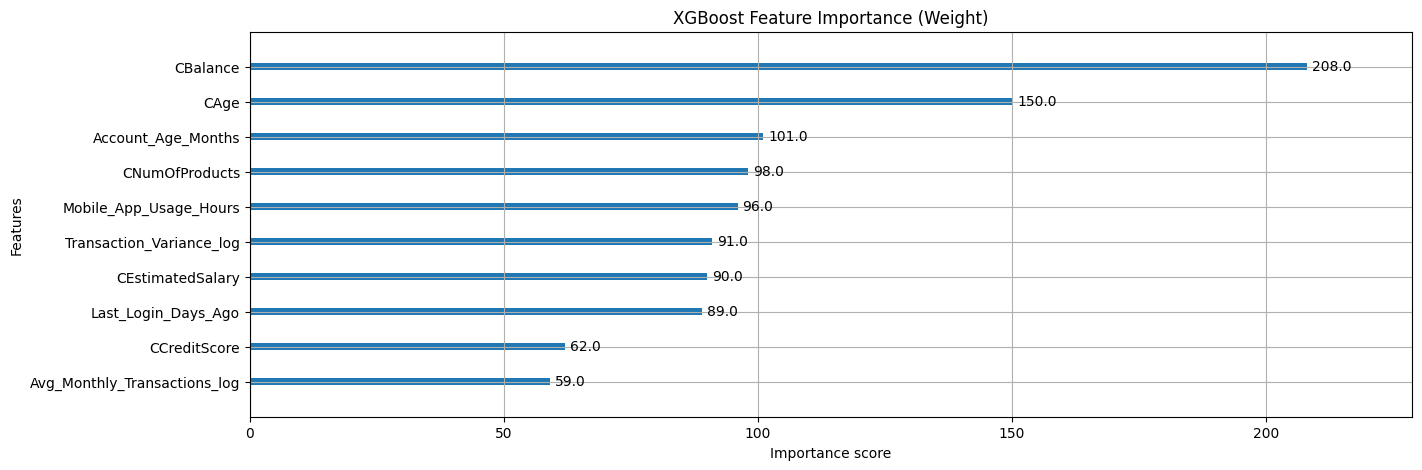

--- Importance Type: Gain ---


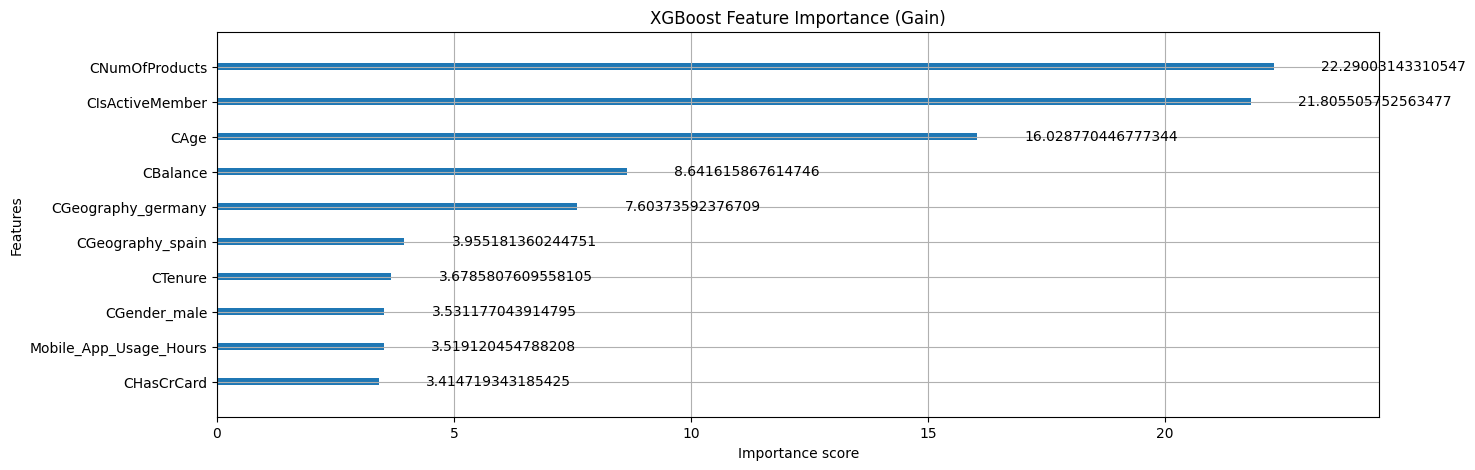

In [9]:
import xgboost as xgb
import matplotlib.pyplot as plt
from matplotlib.pylab import rcParams
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import accuracy_score

print("=== TASK 4: ENSEMBLE LEARNING (XGBOOST) ===")

# ==========================================
# 1. INITIAL ENSEMBLE MODEL (No Tuning)
# ==========================================
# Instantiate the XGBClassifier
xgb_initial = xgb.XGBClassifier(n_estimators=100, random_state=42, eval_metric='error')
xgb_initial.fit(X_train, y_train)

# Accuracy scores for initial model
y_pred_train_xgb = xgb_initial.predict(X_train)
y_pred_test_xgb = xgb_initial.predict(X_test)

print("--- Initial XGBoost (Default Parameters) ---")
print("Accuracy of training data:", accuracy_score(y_train, y_pred_train_xgb))
print("Accuracy of test data:", accuracy_score(y_test, y_pred_test_xgb))
print("Accuracy of cross-validation:", cross_val_score(xgb_initial, X_train, y_train, scoring='accuracy', cv=5).mean())
# Note: Gradient boosting is very susceptible to overfitting, so we expect a gap between Train and CV here.

# ==========================================
# 2. HYPERPARAMETER TUNING
# ==========================================
# Define the grid of hyperparameters to prevent overfitting
params_xgb = {
    'n_estimators': [100, 200],         # Number of boosting rounds
    'max_depth': [3, 4, 5],             # Maximum depth of a tree
    'learning_rate': [0.01, 0.1, 0.2],  # Step size shrinkage
    'subsample': [0.75, 1.0],           # Subsample ratio of training instances
    'colsample_bytree': [0.8, 1.0]      # Subsample ratio of columns
}

# Instantiate a 5-fold CV-grid search object for the ensemble
grid_xgb = GridSearchCV(xgb.XGBClassifier(random_state=42, eval_metric='error'), 
                        param_grid=params_xgb, 
                        scoring='accuracy', 
                        cv=5, 
                        n_jobs=-1)

# Fit CV-grid search object to the training data
print("\nRunning Grid Search for XGBoost... (This might take a minute)")
grid_xgb.fit(X_train, y_train)

# Print the best hyperparameters
print("\n--- Optimized XGBoost ---")
print("Best hyperparameters:\n", grid_xgb.best_params_)

# Extract the best model
best_xgb_model = grid_xgb.best_estimator_

# Accuracy scores for optimized model
print("Accuracy of training data:", accuracy_score(y_train, best_xgb_model.predict(X_train)))
print("Accuracy of test data:", accuracy_score(y_test, best_xgb_model.predict(X_test)))
print("Accuracy of grid search cross-validation:", grid_xgb.best_score_)

# Set up the parameters for plot size
rcParams['figure.figsize'] = 15, 5

print("\n=== XGBOOST FEATURE IMPORTANCE ===")

# 1. Feature Importance by 'Weight' (How many times a feature appears in a tree)
print("--- Importance Type: Weight ---")
# Note: We use 'best_xgb_model' which we extracted from GridSearchCV
xgb.plot_importance(best_xgb_model, importance_type="weight", max_num_features=10)
plt.title("XGBoost Feature Importance (Weight)")
plt.show()

# 2. Feature Importance by 'Gain' (Average gain of splits which use the feature)
print("--- Importance Type: Gain ---")
xgb.plot_importance(best_xgb_model, importance_type="gain", max_num_features=10)
plt.title("XGBoost Feature Importance (Gain)")
plt.show()

### **Task 4: Applying Ensemble Learning (XGBoost)**

In this stage, we implemented **Extreme Gradient Boosting (XGBoost)**, a powerful ensemble technique that combines multiple "weak" decision trees to create a single "strong" predictive model. XGBoost is widely regarded in the industry for its efficiency and high predictive accuracy.

---

#### **1. Initial Model and Overfitting Analysis**
XGBoost works through an iterative process where each new tree is trained to correct the errors of the previous ones. However, this high learning capacity often leads to **High Variance (Overfitting)** if not properly constrained.

Our initial model with default parameters showed a significant performance gap:
* **Training Accuracy:** 0.9997 (99.97%)
* **Test Accuracy:** 0.9359 (93.59%)
* **Cross-Validation Accuracy:** 0.9376 (93.76%)

The near-perfect training score indicates that the default ensemble was "memorizing" specific noise in the training set rather than learning generalizable customer behaviors.



---

#### **2. Hyperparameter Tuning and Optimization**
To improve the model's ability to generalize to new customers, we performed a **Grid Search Cross-Validation**. The optimization process selected the following "regularized" hyperparameters:

* **`max_depth`: 3**: Interestingly, the ensemble performs best with very shallow trees. This prevents individual trees from becoming too complex.
* **`learning_rate`: 0.1**: This "shrinkage" factor ensures that the model learns slowly and steadily, which helps prevent overfitting.
* **`n_estimators`: 200**: The model determined that 200 boosting rounds provided the optimal balance between bias and variance.
* **`colsample_bytree`: 0.8**: Each tree only considers 80% of the features, introducing a layer of randomness that makes the ensemble more robust.

---

#### **3. Final Performance Comparison**
The optimized XGBoost model successfully addressed the overfitting issue and outperformed our previous standalone Decision Tree:

| Metric | Optimized Decision Tree (Task 3) | **Optimized XGBoost (Task 4)** |
| :--- | :--- | :--- |
| **Training Accuracy** | 0.9377 | 0.9536 |
| **Test Accuracy** | 0.9324 | **0.9383** |
| **CV Accuracy** | 0.9357 | **0.9428** |

**Conclusion:** The **Optimized XGBoost** is our final champion model. By utilizing an ensemble of trees and fine-tuning the boosting parameters, we achieved the highest cross-validation score (**94.28%**) and the most stable generalization performance.

---

#### **4. Explainable AI: Feature Importance (Weight vs. Gain)**
To move from "Black Box" predictions to actionable business insights, we analyzed feature importance using two metrics:

* **Importance by Weight:** This counts how many times a feature is used to split data across all 200 trees. It identifies the most "active" variables in the model.
* **Importance by Gain:** This is the most critical metric for the marketing team. It measures the **actual contribution** of each feature to the model's accuracy.



**Strategic Insight:** While some features might appear frequently (High Weight), the **Gain** analysis tells us which features are the "deciding factors" for churn. This allows the bank to focus its retention efforts on the variables that truly drive customer decisions.